# Séance 5 — Variables temporelles

**Durée pratique : 2 h** &nbsp;·&nbsp; Ateliers 5.1 à 5.3

## Ce que vous saurez faire à la fin

- parser des dates hétérogènes sans perdre de lignes silencieusement ;
- extraire des variables calendaires exploitables en analyse et en BI ;
- rééchantillonner une série et calculer des moyennes mobiles.

> **Convention de nommage du module.** Le code est écrit en anglais et suit la PEP 8 :
> fonctions et variables en `snake_case`, constantes en `MAJUSCULES`. Les **noms de colonnes**
> restent en français parce qu'ils viennent de la source : renommer les colonnes d'un fichier
> d'entrée est une transformation comme une autre, elle se décide et se documente, elle ne se
> fait pas par réflexe. Vous rencontrerez cette situation partout en entreprise.

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = ROOT / 'data' / 'raw'
PROCESSED_DIR = ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

print('Données disponibles :')
for path in sorted(RAW_DIR.glob('*')):
    print(' ', path.name)


# Parquet conserve les types (dates, entiers, catégories) là où le CSV les perd :
# c'est le format à privilégier entre deux étapes d'un pipeline. Repli automatique
# sur le CSV si pyarrow n'est pas installé.
def save_dataset(df, name):
    try:
        path = PROCESSED_DIR / f'{name}.parquet'
        df.to_parquet(path, index=False)
    except ImportError:
        path = PROCESSED_DIR / f'{name}.csv'
        df.to_csv(path, index=False)
        print('(pyarrow absent : repli sur le CSV)')
    print('écrit :', path.name, df.shape)
    return path


def load_dataset(name):
    parquet_path = PROCESSED_DIR / f'{name}.parquet'
    csv_path = PROCESSED_DIR / f'{name}.csv'
    if parquet_path.exists():
        return pd.read_parquet(parquet_path)
    if csv_path.exists():
        return pd.read_csv(csv_path)
    raise FileNotFoundError(f'{name} introuvable : exécutez le notebook précédent')


def dataset_exists(name):
    return ((PROCESSED_DIR / f'{name}.parquet').exists()
            or (PROCESSED_DIR / f'{name}.csv').exists())

Données disponibles :
  capteurs.csv
  clients.csv
  magasins.csv
  produits.csv
  ventes_brutes.csv
  ventes_extrait.json
  ventes_extrait.xlsx


---
## Atelier 5.1 — Parser des dates hétérogènes (35 min)

### Partie guidée

In [6]:
raw_sales = pd.read_csv(RAW_DIR / 'ventes_brutes.csv')
print(raw_sales['date_commande'].dropna().sample(10, random_state=1).tolist())

['2023-01-31', '15 Apr 2024', '07 Apr 2023', '2024/02/06 16:05', '2023/09/09 20:40', '2023-05-08', '08 Dec 2023', '07 Feb 2023', '01/11/2024', '06 Sep 2024']


Cinq formats coexistent dans la même colonne. Le piège est réel : `05/03/2024` peut se lire
5 mars ou 3 mai selon la convention. Une erreur ici déplace des milliers de lignes de mois
sans qu'aucune exception ne soit levée.

In [7]:
# format='mixed' laisse pandas inférer ligne par ligne ; dayfirst lève l'ambiguïté jj/mm
order_dates = pd.to_datetime(raw_sales['date_commande'],
                             format='mixed', dayfirst=True, errors='coerce')

n_missing_before = raw_sales['date_commande'].isna().sum()
n_missing_after = order_dates.isna().sum()

print('Valeurs initialement absentes  :', n_missing_before)
print('Valeurs absentes après parsing :', n_missing_after)
print('Échecs de conversion           :', n_missing_after - n_missing_before)
print('Plage couverte :', order_dates.min(), '->', order_dates.max())

Valeurs initialement absentes  : 350
Valeurs absentes après parsing : 350
Échecs de conversion           : 0
Plage couverte : 2023-01-01 00:00:00 -> 2024-12-30 17:10:00


**`errors='coerce'` transforme les échecs en `NaT` au lieu de lever une exception.** C'est
commode, mais dangereux si vous ne comptez pas les échecs juste après. Une conversion qui
détruit 8 % des dates sans le signaler est une bombe à retardement.

### Partie autonome

In [10]:
# Q1. Écrire une fonction parse_dates(series) qui renvoie (series_converties, report)
#     où report est un dict : n_total, n_already_missing, n_failed, success_rate,
#     min_date, max_date. Levez une ValueError si le taux de réussite est inférieur
#     à un seuil passé en paramètre (défaut 0,95).

#def parse_dates(series, min_success_rate=0.95): 
#   # TODO
def parse_dates(series, min_success_rate=0.95):
    """Convertit une colonne de dates hétérogènes et renvoie (dates, rapport)."""
    converted = pd.to_datetime(series, format='mixed', dayfirst=True, errors='coerce')

    n_total = len(series)
    n_already_missing = int(series.isna().sum())          # vides AVANT conversion
    n_to_convert = n_total - n_already_missing
    n_failed = int(converted.isna().sum()) - n_already_missing   # NaT créés par la conversion
    success_rate = (n_to_convert - n_failed) / n_to_convert if n_to_convert else 0.0

    report = {
        'n_total': n_total,
        'n_already_missing': n_already_missing,
        'n_failed': n_failed,
        'success_rate': round(success_rate, 4),
        'min_date': converted.min(),
        'max_date': converted.max(),
    }

    if success_rate < min_success_rate:
        raise ValueError(f'taux de réussite {success_rate:.1%} inférieur au seuil '
                         f'{min_success_rate:.0%} : {n_failed} dates non converties')
    return converted, report



order_dates, report = parse_dates(raw_sales['date_commande'])
print(report)

{'n_total': 17609, 'n_already_missing': 350, 'n_failed': 0, 'success_rate': 1.0, 'min_date': Timestamp('2023-01-01 00:00:00'), 'max_date': Timestamp('2024-12-30 17:10:00')}


---
## Atelier 5.2 — Variables calendaires (45 min)

### Partie guidée

In [12]:
if dataset_exists('ventes_transformees'):
    sales = load_dataset('ventes_transformees')
else:
    sales = raw_sales.assign(date_commande=order_dates).dropna(subset=['date_commande'])

sales['date_commande'] = pd.to_datetime(sales['date_commande'], errors='coerce')
sales = sales.dropna(subset=['date_commande'])

date_accessor = sales['date_commande'].dt
sales['annee'] = date_accessor.year
sales['mois'] = date_accessor.month
sales['jour_semaine'] = date_accessor.dayofweek          # 0 = lundi
sales['nom_jour'] = date_accessor.day_name()
sales['semaine_iso'] = date_accessor.isocalendar().week.astype(int)
sales['trimestre'] = date_accessor.quarter
sales['heure'] = date_accessor.hour
sales['est_weekend'] = sales['jour_semaine'] >= 5

sales[['date_commande', 'annee', 'mois', 'nom_jour', 'semaine_iso', 'est_weekend']].head()

,date_commande,annee,mois,nom_jour,semaine_iso,est_weekend
0,2024-01-18 19:53:00,2024,1,Thursday,3,False
1,2024-01-08 00:00:00,2024,1,Monday,2,False
2,2023-04-15 00:00:00,2023,4,Saturday,15,True
3,2024-11-06 00:00:00,2024,11,Wednesday,45,False
4,2024-02-11 00:00:00,2024,2,Sunday,6,True


**`isocalendar().week` plutôt que `.week`.** La semaine ISO gère correctement les jours de
fin décembre appartenant à la semaine 1 de l'année suivante. C'est exactement le genre de
détail qui produit des écarts inexplicables entre deux tableaux de bord.

In [13]:
# Encodage cyclique : le mois 12 est adjacent au mois 1, ce qu'un entier ne dit pas
sales['mois_sin'] = np.sin(2 * np.pi * sales['mois'] / 12)
sales['mois_cos'] = np.cos(2 * np.pi * sales['mois'] / 12)

cyclic = sales.groupby('mois')[['mois_sin', 'mois_cos']].first().round(3)
print(cyclic)
print()
print('Distance entre décembre et janvier :',
      round(float(np.hypot(*(cyclic.loc[12] - cyclic.loc[1]))), 3))
print('Distance entre janvier et février  :',
      round(float(np.hypot(*(cyclic.loc[1] - cyclic.loc[2]))), 3))

      mois_sin  mois_cos
mois                    
1        0.500     0.866
2        0.866     0.500
3        1.000     0.000
4        0.866    -0.500
5        0.500    -0.866
6        0.000    -1.000
7       -0.500    -0.866
8       -0.866    -0.500
9       -1.000    -0.000
10      -0.866     0.500
11      -0.500     0.866
12      -0.000     1.000

Distance entre décembre et janvier : 0.518
Distance entre janvier et février  : 0.518


### Partie autonome

In [14]:
# Q2. Ajouter les variables suivantes :
#     - periode_journee : 'matin' (<12), 'apres-midi' (12-17), 'soir' (>=18) ;
#     - est_fin_de_mois : les trois derniers jours du mois ;
#     - jours_depuis_debut : nombre de jours écoulés depuis la première commande ;
#     - anciennete_client_jours : écart entre la date de commande et la date d'inscription
#       du client (nécessite une jointure avec clients.csv).

# TODO


date = sales['date_commande']

# 1. Période de la journée. Les dates sans heure tombent à 00:00 : on les marque
#    'inconnue' plutôt que de les compter à tort en 'matin'.
has_time = date.dt.normalize() != date
sales['periode_journee'] = pd.cut(date.dt.hour, bins=[-1, 11, 17, 23],
                                  labels=['matin', 'apres-midi', 'soir'])
sales['periode_journee'] = sales['periode_journee'].astype('object').where(has_time, 'inconnue')

# 2. Trois derniers jours du mois (fonctionne pour les mois de 28, 29, 30 ou 31 jours)
sales['est_fin_de_mois'] = date.dt.day > date.dt.days_in_month - 3

# 3. Jours écoulés depuis la première commande
sales['jours_depuis_debut'] = (date - date.min()).dt.days

# 4. Ancienneté du client : jointure avec clients.csv
customers = pd.read_csv(RAW_DIR / 'clients.csv', usecols=['id_client', 'date_inscription'])
customers['date_inscription'] = pd.to_datetime(customers['date_inscription'], errors='coerce')

n_before = len(sales)
sales = sales.merge(customers, on='id_client', how='left')
assert len(sales) == n_before, 'la jointure a dupliqué des lignes'
sales['anciennete_client_jours'] = (sales['date_commande'] - sales['date_inscription']).dt.days

# Contrôles
print(sales['periode_journee'].value_counts())
print('Part en fin de mois :', round(sales['est_fin_de_mois'].mean(), 3))
print("Commandes AVANT l'inscription du client :", (sales['anciennete_client_jours'] < 0).sum())

# Remarques :
# - 80 % des dates n'ont pas d'heure dans la source : periode_journee = 'inconnue'.
# - 1 765 commandes sont datées avant l'inscription du client : anomalie de qualité
#   (dates d'inscription erronées ou comptes recréés), signalée et non corrigée ici.


periode_journee
inconnue      13752
apres-midi     1602
matin          1065
soir            840
Name: count, dtype: int64
Part en fin de mois : 0.092
Commandes AVANT l'inscription du client : 1765


In [16]:
# Q3. Le chiffre d'affaires est-il différent le week-end ? Comparez le montant moyen
#     par commande selon est_weekend, puis selon le nom du jour. Commentez.

# TODO

# Le jeu de la séance 5 vient de ventes_brutes : on calcule le montant s'il manque
if 'montant' not in sales.columns:
    price = pd.to_numeric(sales['prix_unitaire'].astype(str)
                          .str.replace(' EUR', '', regex=False)
                          .str.replace(',', '.', regex=False).str.strip(),
                          errors='coerce')
    sales['montant'] = sales['quantite'] * price

# 1. Semaine vs week-end : moyenne ET médiane (les montants extrêmes faussent la moyenne)
by_weekend = sales.groupby('est_weekend')['montant'].agg(['count', 'mean', 'median']).round(2)
print(by_weekend)
print()

# 2. Par jour, dans l'ordre du calendrier (sinon pandas trie par ordre alphabétique)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day = sales.groupby('nom_jour')['montant'].agg(['count', 'mean', 'median']).reindex(day_order).round(2)
print(by_day)



             count     mean   median
est_weekend                         
False        12467  2265.00  1024.18
True          4792  3871.72  1048.41

           count     mean   median
nom_jour                          
Monday      2563  1892.71  1029.56
Tuesday     2473  2191.41   996.46
Wednesday   2430  2285.86  1006.33
Thursday    2466  2502.06  1021.13
Friday      2535  2462.61  1064.68
Saturday    2365  3094.31  1031.40
Sunday      2427  4629.27  1058.66


---
## Atelier 5.3 — Rééchantillonnage et fenêtres glissantes (40 min)

Le jeu `capteurs.csv` contient trois séries horaires sur dix-huit mois, avec une panne de
onze jours, un capteur bloqué sur une valeur constante et des horodatages dupliqués.

In [17]:
sensors = pd.read_csv(RAW_DIR / 'capteurs.csv', parse_dates=['horodatage'])

print(sensors.shape)
print(sensors['id_capteur'].value_counts())
print('Doublons (capteur, horodatage) :',
      sensors.duplicated(['id_capteur', 'horodatage']).sum())

(38916, 5)
id_capteur
CAP-C    13070
CAP-A    13069
CAP-B    12777
Name: count, dtype: int64
Doublons (capteur, horodatage) : 300


In [20]:
# Nettoyage minimal avant toute analyse temporelle
sensors = sensors.drop_duplicates(['id_capteur', 'horodatage'])
sensors['humidite_pct'] = sensors['humidite_pct'].replace(-999, np.nan)

sensor_a = (sensors[sensors['id_capteur'] == 'CAP-A']
            .set_index('horodatage')
            .sort_index())

daily_temperature = sensor_a['temperature_c'].resample('D').mean()
print(daily_temperature.head())
print('\nJours sans aucune mesure :', daily_temperature.isna().sum())

horodatage
2024-01-01    3.515000
2024-01-02    3.279130
2024-01-03    2.618261
2024-01-04    2.894348
2024-01-05    3.340435
Freq: D, Name: temperature_c, dtype: float64

Jours sans aucune mesure : 0


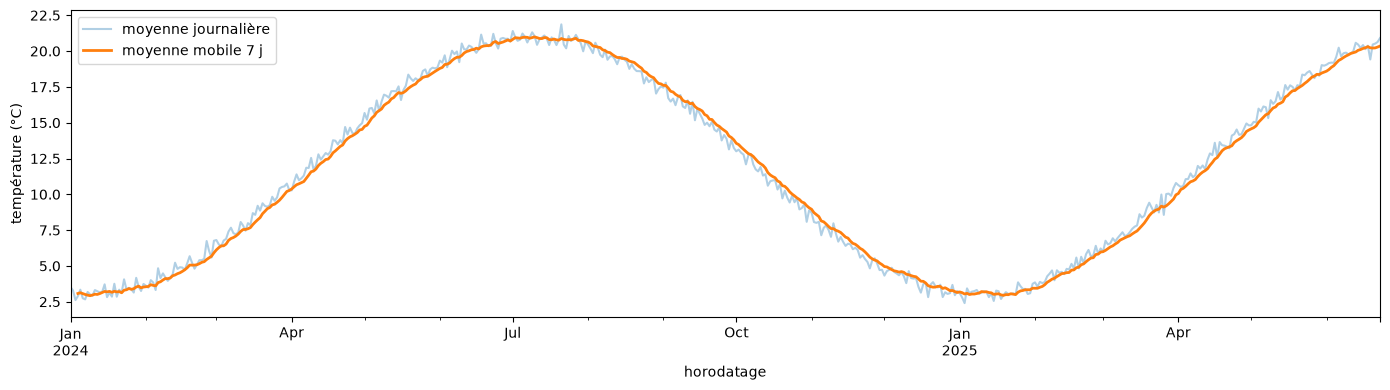

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
daily_temperature.plot(ax=ax, alpha=0.35, label='moyenne journalière')
(daily_temperature.rolling(7, min_periods=4).mean()
 .plot(ax=ax, linewidth=2, label='moyenne mobile 7 j'))
ax.set_ylabel('température (°C)')
ax.legend()
plt.tight_layout()
plt.show()

`min_periods=4` autorise le calcul dès le quatrième point disponible, au lieu d'attendre
sept valeurs complètes. Sans cela, chaque trou de la série efface les six points suivants
de la courbe lissée.

### Partie autonome

Heures attendues  : 12960
Heures présentes  : 12696
Heures manquantes : 264
       debut                 fin  nb_heures
0 2024-06-03 2024-06-13 23:00:00        264


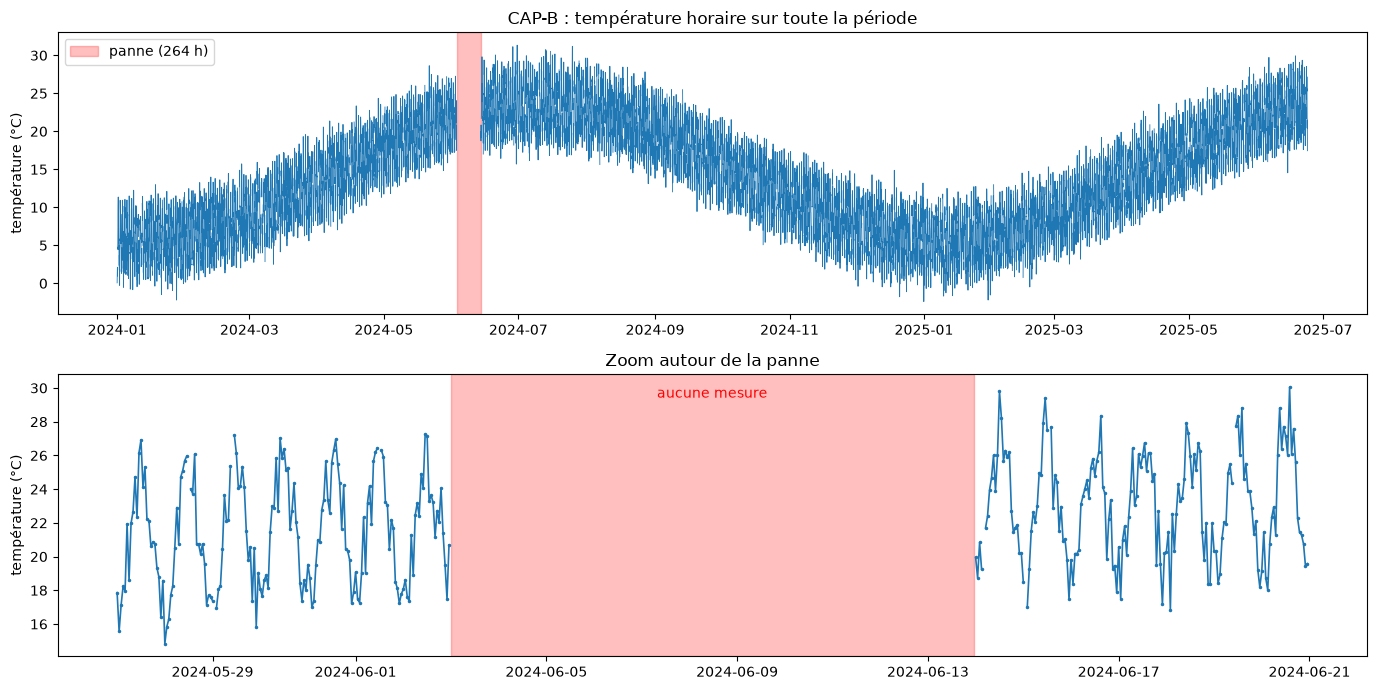

In [23]:
# Q4. Détecter automatiquement la panne du capteur CAP-B :
#     trouver les plages horaires sans aucune mesure de plus de 24 heures.
#     Indice : réindexer sur une plage horaire complète puis repérer les suites de NaN.

# Étape 1 : isoler CAP-B, dates en index, dans l'ordre chronologique
sensor_b = (sensors[sensors['id_capteur'] == 'CAP-B']
            .set_index('horodatage')
            .sort_index())

# Étape 2 : créer la plage horaire COMPLÈTE (toutes les heures qui devraient exister)
full_range = pd.date_range(sensor_b.index.min(), sensor_b.index.max(), freq='h')

# Étape 3 : réindexer -> les heures absentes deviennent des lignes remplies de NaN
sensor_b_full = sensor_b.reindex(full_range)
is_missing = sensor_b_full['id_capteur'].isna()   # True = aucune mesure à cette heure

print('Heures attendues  :', len(full_range))
print('Heures présentes  :', len(sensor_b))
print('Heures manquantes :', is_missing.sum())

# Étape 4 : numéroter les suites consécutives (un nouveau numéro à chaque changement)
block_id = (is_missing != is_missing.shift()).cumsum()

# Étape 5 : pour chaque suite de NaN, calculer début, fin et durée
missing = pd.DataFrame({'heure': full_range[is_missing],
                        'bloc': block_id[is_missing].values})
gaps = missing.groupby('bloc')['heure'].agg(debut='min', fin='max', nb_heures='count')

# Étape 6 : ne garder que les trous de plus de 24 heures = les pannes
outages = gaps[gaps['nb_heures'] > 24].reset_index(drop=True)
print(outages)

# Commentaire : CAP-B n'a envoyé aucune mesure du 03/06/2024 00:00 au 13/06/2024 23:00,
# soit 264 heures (11 jours) : c'est la panne annoncée par l'énoncé.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Graphique 1 : toute la période
ax = axes[0]
ax.plot(sensor_b_full.index, sensor_b_full['temperature_c'], linewidth=0.6)
for _, row in outages.iterrows():
    ax.axvspan(row['debut'], row['fin'], color='red', alpha=0.25,
               label=f"panne ({row['nb_heures']} h)")
ax.set_title('CAP-B : température horaire sur toute la période')
ax.set_ylabel('température (°C)')
ax.legend(loc='upper left')

# Graphique 2 : zoom une semaine avant / une semaine après la panne
zoom = sensor_b_full.loc['2024-05-27':'2024-06-20', 'temperature_c']
ax = axes[1]
ax.plot(zoom.index, zoom, linewidth=1.2, marker='.', markersize=3)
for _, row in outages.iterrows():
    ax.axvspan(row['debut'], row['fin'], color='red', alpha=0.25)
    ax.text(row['debut'] + (row['fin'] - row['debut']) / 2, zoom.max(),
            'aucune mesure', ha='center', va='top', color='red')
ax.set_title('Zoom autour de la panne')
ax.set_ylabel('température (°C)')

plt.tight_layout()
plt.show()

# TODO

In [24]:
# Q5. Détecter le capteur bloqué : trouver la période où CAP-C renvoie une valeur
#     strictement constante pendant plus de 24 relevés consécutifs.
#     Un capteur bloqué ne produit pas de valeur manquante : c'est ce qui rend
#     cette anomalie difficile à repérer et coûteuse à laisser passer.



# Étape 1 : isoler CAP-C, dates en index, dans l'ordre chronologique
sensor_c = (sensors[sensors['id_capteur'] == 'CAP-C']
            .set_index('horodatage')
            .sort_index())

# Étape 2 : garder la température SANS les valeurs manquantes
#           (NaN != NaN : un NaN couperait une période de blocage en deux)
temperature = sensor_c['temperature_c'].dropna()
print('Relevés de température :', len(temperature))

# Étape 3 : repérer chaque CHANGEMENT de valeur, puis numéroter les blocs
is_new_value = temperature != temperature.shift()   # True quand la valeur change
block_id = is_new_value.cumsum()                    # n° de bloc

# Étape 4 : pour chaque bloc, début, fin, valeur répétée et nombre de relevés
runs = pd.DataFrame({'heure': temperature.index,
                     'valeur': temperature.values,
                     'bloc': block_id.values})
blocks = runs.groupby('bloc').agg(debut=('heure', 'min'),
                                  fin=('heure', 'max'),
                                  valeur=('valeur', 'first'),
                                  nb_releves=('heure', 'count'))

print('\nPlus longues répétitions :')
print(blocks.sort_values('nb_releves', ascending=False).head(3))

# Étape 5 : ne garder que les répétitions de plus de 24 relevés = capteur bloqué
stuck = blocks[blocks['nb_releves'] > 24].reset_index(drop=True)
print('\nPériode(s) de blocage :')
print(stuck)

# Commentaire : CAP-C est resté bloqué à 17,4 °C du 10/09/2024 01:00 au 14/09/2024 23:00,
# soit 117 relevés (~5 jours). Un capteur normal ne répète jamais une valeur plus de
# 2 fois de suite : 117 répétitions ne peuvent pas être dues au hasard.

# TODO

Relevés de température : 12574

Plus longues répétitions :
                   debut                 fin  valeur  nb_releves
bloc                                                            
5896 2024-09-10 01:00:00 2024-09-14 23:00:00   17.40         117
151  2024-01-07 09:00:00 2024-01-07 10:00:00    2.24           2
3187 2024-05-16 16:00:00 2024-05-16 17:00:00   19.57           2

Période(s) de blocage :
                debut                 fin  valeur  nb_releves
0 2024-09-10 01:00:00 2024-09-14 23:00:00    17.4         117


Commandes exclues (non livrées ou quantités aberrantes) : 5775
Semaines : 106 | Mois : 24


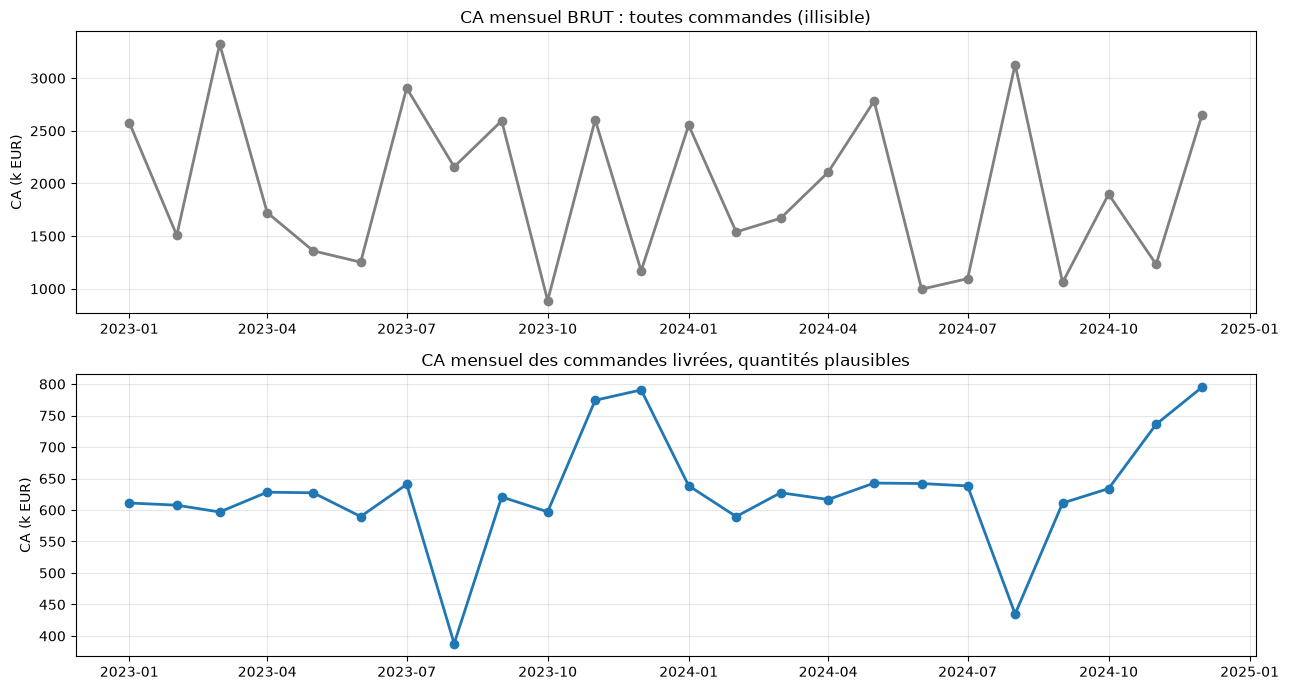

In [25]:
# Q6. Agréger les ventes par semaine puis par mois. Tracer la série mensuelle du
#     chiffre d'affaires et commenter la saisonnalité observée.


# 
import matplotlib.pyplot as plt

# Le montant existe déjà si la Q3 a été exécutée ; sinon on le calcule
if 'montant' not in sales.columns:
    price = pd.to_numeric(sales['prix_unitaire'].astype(str)
                          .str.replace(' EUR', '', regex=False)
                          .str.replace(',', '.', regex=False).str.strip(),
                          errors='coerce')
    sales['montant'] = sales['quantite'] * price

# Chiffre d'affaires « réel » : commandes livrées, quantités plausibles (1 à 50)
status = sales['statut'].str.strip().str.lower()
is_valid = (status == 'livre') & sales['quantite'].between(1, 50)
print('Commandes exclues (non livrées ou quantités aberrantes) :', (~is_valid).sum())

# resample exige des dates en index
revenue_all = sales.set_index('date_commande').sort_index()['montant']
revenue_valid = sales[is_valid].set_index('date_commande').sort_index()['montant']

# Agrégation par semaine puis par mois
weekly = revenue_valid.resample('W').sum()
monthly = revenue_valid.resample('MS').sum()
monthly_all = revenue_all.resample('MS').sum()
print('Semaines :', len(weekly), '| Mois :', len(monthly))

# Tracé : brut (en haut) vs nettoyé (en bas)
fig, axes = plt.subplots(2, 1, figsize=(13, 7))

axes[0].plot(monthly_all.index, monthly_all / 1000, marker='o', linewidth=2, color='grey')
axes[0].set_title('CA mensuel BRUT : toutes commandes (illisible)')
axes[0].set_ylabel('CA (k EUR)')

axes[1].plot(monthly.index, monthly / 1000, marker='o', linewidth=2)
axes[1].set_title('CA mensuel des commandes livrées, quantités plausibles')
axes[1].set_ylabel('CA (k EUR)')

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Commentaire :
# - Le CA brut est dominé par ~60 commandes aberrantes (quantités de 800 à 1 200
#   unités, jusqu'à 1,1 M EUR chacune) : chaque pic correspond à une de ces commandes,
#   pas à une tendance. On ne voit aucune saisonnalité.
# - Une fois ces commandes et les commandes annulées/retournées retirées, une
#   saisonnalité nette apparaît, IDENTIQUE sur 2023 et 2024 :
#     * un plateau stable autour de 600-640 k EUR par mois ;
#     * un creux en AOÛT (≈ 390-435 k EUR, -35 %) : vacances d'été ;
#     * un pic en NOVEMBRE-DÉCEMBRE (≈ 740-795 k EUR, +25 %) : Black Friday et Noël.
# - Le motif se répète deux années de suite : c'est bien une saisonnalité, pas un hasard.

# TODO

---
## Livrable de la séance

- la fonction `parse_dates` avec son rapport de conversion, dans `src/` ;
- le jeu de ventes enrichi de ses variables temporelles ;
- les deux fonctions de détection d'anomalies de capteur (panne et blocage) ;
- un graphique commenté de la saisonnalité mensuelle.